# CNN — MIT 数据集

**特征方案**：V + I + T

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False
import pickle
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from copy import deepcopy
from sklearn.model_selection import train_test_split
from itertools import product


In [ ]:
# 加载最终数据
bat_dict = pickle.load(open(r"D:\Python\data_bag\MIT_data\processed\DATA_bat_dict.pkl", "rb"))
print(f"数据加载成功！共 {len(bat_dict)} 个电池\n")

# 快速查看一个电池的结构
demo = bat_dict["b1c5"]
print(f"示例电池 b1c5:")
print(f"  cycle_life: {demo['cycle_life']}")
print(f"  charge_policy: {demo['charge_policy']}")
print(f"  summary keys: {list(demo['summary'].keys())}")
print(f"  cycles 数量: {len(demo['cycles'])}")
print(f"  QD_fixed 长度: {len(demo['summary']['QD_fixed'])}")

数据加载成功！共 124 个电池

示例电池 b1c5:
  cycle_life: [[1074.]]
  charge_policy: 4.4C(80%)-4.4C
  summary keys: ['IR', 'QC', 'QD', 'Tavg', 'Tmin', 'Tmax', 'chargetime', 'cycle', 'QD_fixed', 'knee_onset', 'knee_point', 'eol_cycle', 'RUL']
  cycles 数量: 1073
  QD_fixed 长度: 1073


放电段长度统计: min=104, median=422, mean=385, 99%分位长度=458, max=10505

FIXED_LEN=458


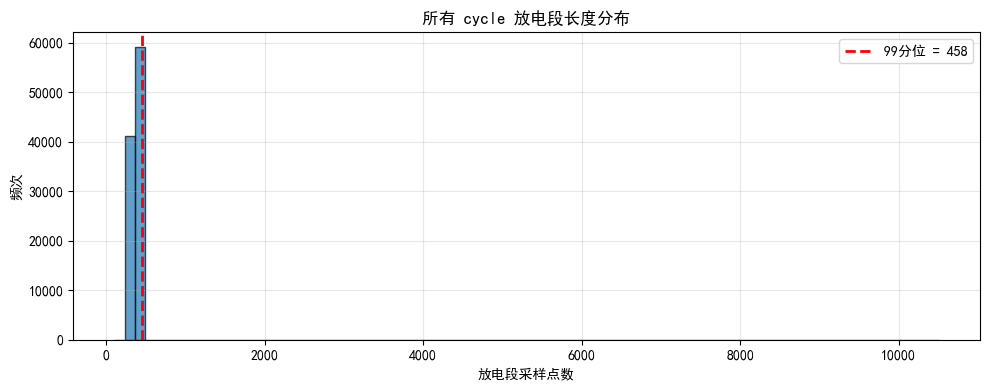

In [ ]:
# ============================================================
# 计算全局 99 分位放电段长度
# ============================================================
all_lengths = []
for name in bat_dict:
    cycles_dict = bat_dict[name]['cycles']
    for cyc_key in cycles_dict:
        cy = cycles_dict[cyc_key]
        I = np.asarray(cy['I'])
        mask = I < -0.01  # 放电段
        n_discharge = mask.sum()
        if n_discharge >= 10:
            all_lengths.append(n_discharge)

all_lengths = np.array(all_lengths)
FIXED_LEN = int(np.percentile(all_lengths, 99))

print(f"放电段长度统计: min={all_lengths.min()}, median={np.median(all_lengths):.0f}, "
      f"mean={all_lengths.mean():.0f}, 99%分位长度={FIXED_LEN}, max={all_lengths.max()}\n")
print(f"FIXED_LEN={FIXED_LEN}") # 只有下个cell中方案1需要用到

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(all_lengths, bins=80, edgecolor='k', alpha=0.7)
ax.axvline(FIXED_LEN, color='r', linestyle='--', linewidth=2,label=f'99分位 = {FIXED_LEN}')
ax.set_xlabel('放电段采样点数')
ax.set_ylabel('频次')
ax.set_title('所有 cycle 放电段长度分布')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# ============================================================
# 特征提取函数（两种预处理方案）
#   方案1 'raw'      : 放电段原始采样点，全局 99 分位定长 + 尾部 zero-padding/截断
#   方案2 'resample' : 放电段按累计放电容量 Q=∫(-I)dt 均匀重采样到固定点数（容量对齐，无信息丢失）
# 通过 PREPROC_MODE 切换，FEAT_DIM 自动跟随
# ============================================================

PREPROC_MODE = 'resample'      # 选 'raw' 或 'resample'
RESAMPLE_LEN = 200             # 方案2 固定采样点数（对应上个cell标注的 200 点）


def extract_cycle_timeseries(V, I, T, fixed_len=FIXED_LEN):
    """方案1：放电段原始时间分辨率，短于 fixed_len 尾部 zero-padding，长于则截断尾部。"""
    mask = I < -0.01
    if mask.sum() < 10:
        mask = np.ones(len(I), dtype=bool)

    V_d = np.asarray(V[mask], dtype=np.float32)
    I_d = np.asarray(I[mask], dtype=np.float32)
    T_d = np.asarray(T[mask], dtype=np.float32)
    n = len(V_d)

    feat = np.zeros(fixed_len * 3, dtype=np.float32)
    if n <= fixed_len:      # 短于 FIXED_LEN：尾部 zero-padding
        feat[0: n] = V_d
        feat[fixed_len: fixed_len+n] = I_d
        feat[2*fixed_len: 2*fixed_len+n] = T_d
    else:                   # 长于 FIXED_LEN：截断尾部
        feat[0: fixed_len] = V_d[:fixed_len]
        feat[fixed_len: 2*fixed_len] = I_d[:fixed_len]
        feat[2*fixed_len: 3*fixed_len] = T_d[:fixed_len]
    return feat


def extract_cycle_timeseries_resample(V, I, T, t=None, n_points=RESAMPLE_LEN):
    """方案2：放电段按累计放电容量 Q=∫(-I)dt 均匀重采样到 n_points 个点。
    以容量为横轴对齐各 cycle（等价 SOC 对齐），所有 cycle 输出长度一致，
    保留完整放电曲线，无需截断/padding。
    t 传入时按容量对齐；t 缺失时退回按采样点下标对齐。
    Returns: (n_points * 3,) float32
    """
    mask = I < -0.01
    if mask.sum() < 10:
        mask = np.ones(len(I), dtype=bool)

    V_d = np.asarray(V[mask], dtype=np.float32)
    I_d = np.asarray(I[mask], dtype=np.float32)
    T_d = np.asarray(T[mask], dtype=np.float32)
    n = len(V_d)

    if t is not None:
        t_d = np.asarray(t[mask], dtype=np.float64)
        dt = np.diff(t_d, prepend=t_d[0])        # 每段时长
        x = np.cumsum(-I_d * dt)                  # 累计放电容量，单调递增
    else:
        x = np.arange(n, dtype=np.float64)        # 退化为下标对齐

    x_new = np.linspace(x[0], x[-1], n_points)
    feat = np.zeros(n_points * 3, dtype=np.float32)
    feat[0: n_points]             = np.interp(x_new, x, V_d)
    feat[n_points: 2*n_points]    = np.interp(x_new, x, I_d)
    feat[2*n_points: 3*n_points]  = np.interp(x_new, x, T_d)
    return feat


def extract_cycle_timeseries_auto(V, I, T, t=None):
    """按 PREPROC_MODE 分发到对应方案。"""
    if PREPROC_MODE == 'raw':
        return extract_cycle_timeseries(V, I, T)
    return extract_cycle_timeseries_resample(V, I, T, t=t)


# 特征维度由所选方案决定
if PREPROC_MODE == 'raw':
    FEAT_DIM = FIXED_LEN * 3
    print(f"预处理方案: raw       | 特征维度 {FEAT_DIM} ({FIXED_LEN}x3, 短pad/长截断)")
else:
    FEAT_DIM = RESAMPLE_LEN * 3
    print(f"预处理方案: resample  | 特征维度 {FEAT_DIM} ({RESAMPLE_LEN}x3, 按容量Q重采样)")

预处理方案: resample  | 特征维度 600 (200x3, 按容量Q重采样)


In [ ]:
# ============================================================
# 数据集构建：缓存 + 滑动窗口 + 训练/验证/测试划分
# ============================================================

def build_dataset(
    bat_dict,
    window_size=5,
    stride=3,
    train_ratio=0.70,
    val_ratio=0.15,
    test_ratio=0.15,
    seed=42,
    verbose=True,
):
    """构建 CNN 容量预测数据集。

    流程：
    1. 按 cycle_life 三分位分层划分电池级 70/15/15
    2. 每个 cycle 提取 V/I/T 时序，缓存为数组
    3. 滑动窗口 (window_size, stride) 生成样本索引
    4. Z-score 归一化（训练集统计量）

    Returns:
        datasets: 归一化的{'train': (samples, y_dict), 'val': ..., 'test': ...}，其中samples 为 [(name, w)]，y_dict 为 {[capacity列表]}
        bat_features: {name: [(n_cycles, FEAT_DIM)]}
        bat_meta: {name: {qd_fixed, cycle_nums, valid_indices}}
        meta: {train_names, window_size, feat_dim, norm params, ...}
    """

    # ---------- 1. 电池级分层划分 ----------
    all_names = sorted(bat_dict.keys())
    cycle_lifes = np.array([float(np.asarray(bat_dict[n]['cycle_life']).ravel()[0]) for n in all_names])    # 展平为一维数组

    # cycle_life 三分位分层
    tertile_edges = np.quantile(cycle_lifes, [0, 1/3, 2/3, 1])
    tertile_edges[0] -= 1
    tertile_edges[-1] += 1
    cycle_bins = np.digitize(cycle_lifes, tertile_edges[1:-1])  # cycle_bins返回值: 0/1/2 对应三分位分组

    if verbose:
        for b in range(3):
            mask = cycle_bins == b  # mask 为 bool 数组，True 表示属于分组 b
            lo, hi = cycle_lifes[mask].min(), cycle_lifes[mask].max()
            print(f"  寿命分组 {b}: {mask.sum()} 电池, 范围 [{lo:.0f}, {hi:.0f}]")
        print()

    names_temp, names_test = train_test_split(all_names, test_size=test_ratio, random_state=seed, stratify=cycle_bins)
    val_adj = val_ratio / (train_ratio + val_ratio)
    temp_bins = cycle_bins[[all_names.index(n) for n in names_temp]]
    names_train, names_val = train_test_split(names_temp, test_size=val_adj, random_state=seed, stratify=temp_bins)

    if verbose:
        print(f"数据集划分: train={len(names_train)}, val={len(names_val)}, test={len(names_test)}\n")

    # ---------- 2. 特征缓存 + 滑动窗口 ----------
    bat_features = {}
    bat_meta = {}

    def _build_cache_and_samples(name_list):
        """
        缓存所有电池的 cycle 特征，并生成滑动窗口样本
        Args:
            name_list: 电池名称列表
        Returns:
            samples: 样本索引列表 [(name, w)]
            y_dict: 字典 {[capacity列表]}
        """
        samples = []
        y_cap = []

        for name in name_list:
            b = bat_dict[name]
            cycles_dict = b['cycles']   # 细点
            summary = b['summary']      # 粗点
            qd_fixed = np.asarray(summary['QD_fixed'], dtype=np.float64)
            cycle_nums = np.asarray(summary['cycle'], dtype=np.int64)

            # 在 “粗点” 中 找到同时存在于 cycles dict（细点） 和 QD_fixed（粗点） 的有效索引
            valid_indices = [
                i for i, cn in enumerate(cycle_nums)
                if str(int(cn)) in cycles_dict and i < len(qd_fixed)
            ]
            n_valid = len(valid_indices)    # 每个粗点中的有效细点数量
            if n_valid < window_size:
                continue

            # 每个 cycle 提取一次特征
            cached = np.empty((n_valid, FEAT_DIM), dtype=np.float32)
            for slot, idx in enumerate(valid_indices):
                cy = cycles_dict[str(int(cycle_nums[idx]))]
                ts_feat = extract_cycle_timeseries_auto(cy['V'], cy['I'], cy['T'], cy['t'])  # 按 PREPROC_MODE 分发
                cached[slot] = ts_feat              # 只使用时序特征

            bat_features[name] = cached         #  (n_cycles, FEAT_DIM)
            bat_meta[name] = {
                'qd_fixed':     qd_fixed,
                'cycle_nums':   cycle_nums,
                'valid_indices': valid_indices,
            }

            # 滑动窗口
            n_windows = n_valid - window_size + 1
            for w in range(0, n_windows, stride):
                last_idx = valid_indices[w + window_size - 1]
                samples.append((name, w))
                y_cap.append(qd_fixed[last_idx])

        y_dict = {
            'capacity': np.array(y_cap, dtype=np.float32),
        }
        return samples, y_dict

    if verbose:
        print(f"构建训练集...")
    s_train, y_train = _build_cache_and_samples(names_train)
    if verbose:
        print(f"  train: {len(s_train)} 窗口")

    if verbose:
        print("构建验证集...")
    s_val, y_val = _build_cache_and_samples(names_val)
    if verbose:
        print(f"  val: {len(s_val)} 窗口")

    if verbose:
        print("构建测试集...")
    s_test, y_test = _build_cache_and_samples(names_test)
    if verbose:
        print(f"  test: {len(s_test)} 窗口")

    total_cycles = sum(v.shape[0] for v in bat_features.values())
    print(f"  特征缓存: {len(bat_features)} 电池, {total_cycles} 周期, "
          f"{total_cycles * FEAT_DIM * 3 / 1024**2:.0f} MiB")

    # ---------- 3. Z-score 归一化（训练集统计量）----------
    # 增量计算 mean
    n_elems, sum_f = 0, np.zeros(FEAT_DIM, dtype=np.float64)
    for name in names_train:
        if name in bat_features:
            f = bat_features[name]
            sum_f += f.sum(axis=0)
            n_elems += f.shape[0]
    feat_mean = (sum_f / n_elems).astype(np.float32)

    # 增量计算 std
    sum_sq = np.zeros(FEAT_DIM, dtype=np.float64)
    for name in names_train:
        if name in bat_features:
            sum_sq += ((bat_features[name] - feat_mean) ** 2).sum(axis=0)
    feat_std = np.sqrt(sum_sq / n_elems).astype(np.float32) + 1e-8

    # 原地归一化
    for feats in bat_features.values():
        feats -= feat_mean
        feats /= feat_std

    # 标签归一化
    cap_mean = y_train['capacity'].mean()
    cap_std  = y_train['capacity'].std() + 1e-8

    for yd in [y_train, y_val, y_test]:
        yd['capacity_norm'] = (yd['capacity'] - cap_mean) / cap_std

    datasets = {
        'train': (s_train, y_train),
        'val':   (s_val,   y_val),
        'test':  (s_test,  y_test),
    }

    meta = {
        'train_names': names_train,
        'val_names':   names_val,
        'test_names':  names_test,
        'feat_mean':   feat_mean,
        'feat_std':    feat_std,
        'cap_mean':    cap_mean,
        'cap_std':     cap_std,
        'window_size': window_size,
        'stride':      stride,
        'fixed_len':     FIXED_LEN,
        'preproc_mode':  PREPROC_MODE,
        'resample_len':  RESAMPLE_LEN,
        'feat_dim':    FEAT_DIM,
    }

    if verbose:
        print(f"\n数据准备完成")
        print(f"  输入形状: ({window_size}, {FEAT_DIM})  (window_size x feat_dim)")
        print(f"  容量归一化: mean={cap_mean:.3f}, std={cap_std:.3f}")

    return datasets, bat_features, bat_meta, meta


# ---------- 执行 ----------
datasets, bat_features, bat_meta, meta = build_dataset(
    bat_dict,
    window_size=5,
    stride=3,
    train_ratio=0.70,
    val_ratio=0.15,
    test_ratio=0.15,
    seed=42,
)

(s_train, y_train) = datasets['train']
(s_val,   y_val)   = datasets['val']
(s_test,  y_test)  = datasets['test']

print(f"\n最终数据统计:")
print(f"  train: {len(s_train)} 窗口, val: {len(s_val)} 窗口, test: {len(s_test)} 窗口")
print(f"  容量范围: train [{y_train['capacity'].min():.3f}, {y_train['capacity'].max():.3f}]")

  寿命分组 0: 41 电池, 范围 [148, 534]
  寿命分组 1: 41 电池, 范围 [535, 860]
  寿命分组 2: 42 电池, 范围 [862, 2237]

数据集划分: train=86, val=19, test=19

构建训练集...
  train: 23077 窗口
构建验证集...
  val: 5341 窗口
构建测试集...
  test: 4917 窗口
  特征缓存: 124 电池, 100377 周期, 172 MiB

数据准备完成
  输入形状: (5, 600)  (window_size x feat_dim)
  容量归一化: mean=1.032, std=0.052

最终数据统计:
  train: 23077 窗口, val: 5341 窗口, test: 4917 窗口
  容量范围: train [0.827, 1.098]


In [ ]:
# ============================================================
# 模型定义：CNN1D + ECA(CNN后注意力) + Transformer Encoder + Attention Pooling(Transformer后注意力)
# 输入 X: (B, window_size=5, FEAT_DIM=600=3×200, 通道 V/I/T)
# ============================================================
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"使用设备: {device}")


class BatteryDataset(Dataset):
    """懒加载 Dataset：从缓存中按窗口索引取数据（容量单标签）"""

    def __init__(self, samples, y_dict, bat_features, window_size,
                 cap_mean=None, cap_std=None):
        self.samples = samples
        self.bat_features = bat_features
        self.window_size = window_size
        self.capacity = torch.from_numpy(y_dict['capacity'])

        self.cap_mean = torch.tensor(cap_mean) if cap_mean is not None else self.capacity.float().mean()
        self.cap_std  = torch.tensor(cap_std)  if cap_std  is not None else self.capacity.float().std() + 1e-8

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        name, w = self.samples[idx]                                             # bat_features: {name: [(n_cycles, FEAT_DIM)]}
        X = torch.from_numpy(self.bat_features[name][w:w + self.window_size])   # X (window_size, 600)    
        cap_norm = (self.capacity[idx] - self.cap_mean) / self.cap_std
        return X, cap_norm


class ECAAttention(nn.Module):
    """ECA 通道注意力模块（输入 (B, T, C)，dim1=时间/序列、dim2=通道）。
    对 5 个 cycle token 的特征通道维做自适应卷积注意力。
    kernel_size: 1D 卷积核大小，默认 None 则自适应计算"""

    def __init__(self, channels, kernel_size=None):
        super().__init__()
        if kernel_size is None:
            import math
            kernel_size = int(abs(math.log2(channels) / 2 + 0.5))
            if kernel_size % 2 == 0:
                kernel_size += 1
        self.gap = nn.AdaptiveAvgPool1d(1)          # (B, C, T) -> (B, C, 1)
        self.conv = nn.Conv1d(1, 1, kernel_size=kernel_size,
                              padding=kernel_size // 2, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):            # x: (B, T, C)
        y = self.gap(x.transpose(1, 2))     # (B, C, 1)
        y = y.squeeze(-1).unsqueeze(1)      # (B, 1, C)
        y = self.conv(y)                    # (B, 1, C) 沿通道维卷积
        y = self.sigmoid(y)                 # (B, 1, C) 各通道注意力权重
        return x * y                        # 权重乘回特征


class CNN1DTransformer(nn.Module):
    """CNN1D(逐 cycle 共享) → ECA(token 通道注意力) → +位置编码 → Transformer Encoder
       → Attention Pooling → MLP → 容量。输入 (B, 5, 600)。"""

    def __init__(self, feat_dim=600, resample_len=200, window_size=5,
                 conv_channels=None, d_model=128, nhead=4, num_layers=2,
                 dim_feedforward=256, dropout=0.1):
        super().__init__()
        n_channels = feat_dim // resample_len            # n_channels = 3   (V/I/T)
        if conv_channels is None:
            conv_channels = d_model                      # CNN 输出通道默认 = d_model，token 直接进 Transformer
        self.resample_len = resample_len
        self.n_channels = n_channels
        self.window_size = window_size
        self.d_model = d_model

        # ---- CNN1D：3→32→64→128 通道，长度 200→100→50→25→1 ----
        self.cnn = nn.Sequential(
            nn.Conv1d(n_channels, 32, kernel_size=7, stride=2, padding=3),    # 200→100
            nn.BatchNorm1d(32),
            nn.ReLU(inplace=True),
            nn.Conv1d(32, 64, kernel_size=5, stride=2, padding=2),            # 100→50
            nn.BatchNorm1d(64),
            nn.ReLU(inplace=True),
            nn.Conv1d(64, conv_channels, kernel_size=3, stride=2, padding=1), # 50→25
            nn.BatchNorm1d(conv_channels),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool1d(1),                                          # 25→1
        )

        # ---- CNN 后注意力：ECA 通道注意力（作用于 5 个 cycle token, (B,5,128)）----
        self.eca = ECAAttention(conv_channels)

        # ---- 位置编码（learned，5 个位置）----
        self.pos_embed = nn.Embedding(window_size, d_model)

        # ---- Transformer Encoder ----
        self.transformer = nn.TransformerEncoder(
            nn.TransformerEncoderLayer(
                d_model=d_model, nhead=nhead, dim_feedforward=dim_feedforward,
                dropout=dropout, activation='gelu', batch_first=True,
            ),
            num_layers=num_layers,
        )

        # ---- Transformer 后注意力：Attention Pooling + 回归头 ----
        self.attn = nn.Linear(d_model, 1)
        self.shared = nn.Sequential(
            nn.Linear(d_model, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
        )
        self.cap_head = nn.Linear(64, 1)

    def forward(self, X):
        B, T, D = X.shape
        x = X.reshape(B, T, self.n_channels, self.resample_len)   # (B,5,3,200) 通道轴=(V,I,T)
        x = x.reshape(B * T, self.n_channels, self.resample_len)  # (B*5,3,200) 共享卷积
        x = self.cnn(x)                                           # (B*5,128,1)
        x = x.squeeze(-1).reshape(B, T, self.d_model)             # (B,5,128) 5 个 cycle token
        x = self.eca(x)                                           # (B,5,128)  CNN后 ECA

        pos_idx = torch.arange(T, device=X.device).unsqueeze(0)   # (1,5)，必须带 device
        x = x + self.pos_embed(pos_idx)                           # (B,5,128)

        x = self.transformer(x)                                   # (B,5,128)
        attn_w = torch.softmax(self.attn(x), dim=1)               # (B,5,1)  Transformer后注意力
        pooled = (attn_w * x).sum(dim=1)                          # (B,128)
        h = self.shared(pooled)                                   # (B,64)
        return self.cap_head(h).squeeze(-1)                       # (B,)


# ---- 形状 + 参数量自测（必跑，确认 reshape 与 Conv 长度正确）----
print("\n=== CNN1DTransformer 形状测试 ===")
_test = CNN1DTransformer(
    feat_dim=meta['feat_dim'], resample_len=meta['resample_len'],
    window_size=meta['window_size'],
    d_model=128, nhead=4, num_layers=2, dim_feedforward=256, dropout=0.1,
).to(device)
_x_test = torch.randn(4, meta['window_size'], meta['feat_dim']).to(device)
_test.train()
_pred = _test(_x_test)
print(f"测试输入 X:    {tuple(_x_test.shape)}")
print(f"测试输出 pred: {tuple(_pred.shape)}")          # 期望 (4,)
print(f"测试参数量:    {sum(p.numel() for p in _test.parameters()):,}")
_test.eval()
with torch.no_grad():
    print(f"测试eval 输出: {tuple(_test(_x_test).shape)}")
del _test, _x_test, _pred
torch.cuda.empty_cache()
print("\n模型定义完成")


使用设备: cuda

=== CNN1DTransformer 形状测试 ===
测试输入 X:    (4, 5, 600)
测试输出 pred: (4,)
测试参数量:    441,799
测试eval 输出: (4,)

模型定义完成


In [ ]:
# ============================================================
# 训练工具函数 + Dataset 构建
# ============================================================

ws = meta['window_size']

# 构建 Dataset（训练集自算统计量，val/test 使用训练集统计量）
train_set = BatteryDataset(s_train, y_train, bat_features, ws)
cap_mean_np = train_set.cap_mean.item()
cap_std_np  = train_set.cap_std.item()
val_set  = BatteryDataset(s_val,  y_val,  bat_features, ws,
                          cap_mean_np, cap_std_np)
test_set = BatteryDataset(s_test, y_test, bat_features, ws,
                          cap_mean_np, cap_std_np)

print(f"Dataset 构建完成: train={len(train_set)}, val={len(val_set)}, test={len(test_set)}")
print(f"容量归一化: mean={cap_mean_np:.3f}, std={cap_std_np:.3f}")


def run_epoch(model, loader, optimizer, loss_fn, device,
              training=True, max_norm=1.0, aux_weight=1.0):
    """训练/验证一个 epoch（容量损失 MSE + MoE 辅助损失）
        目前未加入 MoE模型"""
    if training:
        model.train()
    else:
        model.eval()

    total_loss, n = 0.0, 0
    for X_b, cap_tgt in loader:
        X_b = X_b.to(device)
        cap_tgt = cap_tgt.to(device)
        cap_pred = model(X_b)
        loss = loss_fn(cap_pred, cap_tgt)
        # MoE 辅助损失：仅训练时加权进 loss，val 保持纯 MSE
        aux = getattr(model, 'last_aux_loss', None)
        if training and aux is not None:
            loss = loss + aux_weight * aux

        if training:
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm)
            optimizer.step()

        total_loss += loss.item() * len(X_b)
        n += len(X_b)
    return total_loss / n


def train_model(model, train_set, val_set, device,
                epochs=1000, batch_size=128, lr=1e-4,
                patience=50, verbose=True): 
    """训练模型，返回最佳状态和训练历史"""
    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
    val_loader   = DataLoader(val_set,   batch_size=batch_size, shuffle=False)

    loss_fn = nn.MSELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=5e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=8)

    best_state = deepcopy(model.state_dict())
    best_val, stale = float('inf'), 0
    history = {'train': [], 'val': []}

    for ep in range(epochs):
        tr_loss = run_epoch(model, train_loader, optimizer, loss_fn,
                            device, training=True)
        vl_loss = run_epoch(model, val_loader, optimizer, loss_fn,
                            device, training=False)
        scheduler.step(vl_loss)
        history['train'].append(tr_loss)
        history['val'].append(vl_loss)

        if vl_loss < best_val:
            best_val = vl_loss
            best_state = deepcopy(model.state_dict())
            stale = 0
        else:
            stale += 1

        if verbose and (ep % 10 == 0 or ep == epochs - 1):
            print(f"  Epoch {ep+1:3d}/{epochs}  tr={tr_loss:.4f}  vl={vl_loss:.4f}  "
                  f"lr={optimizer.param_groups[0]['lr']:.1e}")

        if stale >= patience:
            if verbose:
                print(f"  早停于 epoch {ep+1}")
            break

    model.load_state_dict(best_state)
    return model, history


Dataset 构建完成: train=23077, val=5341, test=4917
容量归一化: mean=1.032, std=0.052


In [ ]:
import random
np.random.seed(1)
random.seed(1)
torch.manual_seed(1)
torch.cuda.manual_seed(1)


In [ ]:
# ============================================================
# 网格搜索超参寻优: lr x d_model x nhead x num_layers x dim_feedforward
#   - 目标 = min val_loss（归一化容量 MSE）
#     搜索过程中保存最佳 state_dict，结束后直接加载（不再二次重训）
#   - conv_channels 默认 = d_model
#   - 注意: nhead 需整除 d_model
# ============================================================
from itertools import product

lr_list               = [1e-4, 5e-4]
d_model_list          = [64, 128]
nhead_list            = [4, 8]
num_layers_list       = [1, 2]
dim_feedforward_list  = [256, 512]

candidates = list(product(lr_list, d_model_list, nhead_list,
                          num_layers_list, dim_feedforward_list))
TOTAL = len(candidates)
print(f"网格搜索开始: {len(lr_list)}x{len(d_model_list)}x{len(nhead_list)}"
      f"x{len(num_layers_list)}x{len(dim_feedforward_list)} = {TOTAL} 组")

all_results = []                     # (lr, dm, nh, nl, ff, vl, tr, n_params)
best_tracker = {'vl': float('inf'), 'params': None, 'state': None}

for i, (lr, dm, nh, nl, ff) in enumerate(candidates, 1):
    # 每组重新播种：同参 -> 同结果，搜索可复现
    np.random.seed(1); random.seed(1)
    torch.manual_seed(1); torch.cuda.manual_seed_all(1)

    temp_model = CNN1DTransformer(
        feat_dim=meta['feat_dim'], resample_len=meta['resample_len'],
        window_size=meta['window_size'], dropout=0.1,
        d_model=dm, nhead=nh, num_layers=nl, dim_feedforward=ff,
    ).to(device)

    n_params = sum(p.numel() for p in temp_model.parameters())

    temp_model, history = train_model(
        temp_model, train_set, val_set, device,
        epochs=1000, batch_size=128, lr=lr,
        patience=50, verbose=False,
    )

    vl = min(history['val'])
    idx = history['val'].index(vl)
    tr = history['train'][idx]

    all_results.append((lr, dm, nh, nl, ff, vl, tr, n_params))

    marker = "  <- 当前最佳" if vl < best_tracker['vl'] else ""
    print(f"[{i}/{TOTAL}] lr={lr:.1e}  d_model={dm:3d}  nhead={nh}  "
          f"num_layers={nl}  ffn={ff:4d}  |  val_loss={vl:.4f}  "
          f"tr_loss={tr:.4f}  params={n_params:,}{marker}", flush=True)

    if vl < best_tracker['vl']:
        best_tracker['vl'] = vl
        best_tracker['params'] = (lr, dm, nh, nl, ff)
        best_tracker['state'] = {k: v.cpu().clone()
                                 for k, v in temp_model.state_dict().items()}

    del temp_model
    torch.cuda.empty_cache()

# ---------- 汇总表（按 val_loss 升序） ----------
print(f"\n{'='*72}")
print(f"{'lr':<9} {'d_model':<8} {'nhead':<8} {'num_layers':<12} {'ffn':<6} "
      f"{'val_loss':<12} {'tr_loss':<12} {'params':<10}")
print("-" * 72)
for lr, dm, nh, nl, ff, vl, tr, np_ in sorted(all_results, key=lambda r: r[5]):
    mark = " <- 最佳" if (lr, dm, nh, nl, ff) == best_tracker['params'] else ""
    print(f"{lr:<9.1e} {dm:<8} {nh:<8} {nl:<12} {ff:<6} "
          f"{vl:<12.4f} {tr:<12.4f} {np_:<10,}{mark}")

best_params = best_tracker['params']
print(f"\n最佳参数: lr={best_params[0]:.1e}, d_model={best_params[1]}, "
      f"nhead={best_params[2]}, num_layers={best_params[3]}, "
      f"dim_feedforward={best_params[4]}  (val_loss={best_tracker['vl']:.4f})")

# ---------- 加载最佳模型 ----------
model = CNN1DTransformer(
    feat_dim=meta['feat_dim'], resample_len=meta['resample_len'],
    window_size=meta['window_size'], dropout=0.1,
    d_model=best_params[1], nhead=best_params[2], num_layers=best_params[3],
    dim_feedforward=best_params[4],
).to(device)
model.load_state_dict(best_tracker['state'])
model.eval()
print("最佳模型已加载")


网格搜索开始: 2x2x2x2x2 = 32 组
[1/32] lr=1.0e-04  d_model= 64  nhead=4  num_layers=1  ffn= 256  |  val_loss=0.0457  tr_loss=0.0353  params=78,277  <- 当前最佳
[2/32] lr=1.0e-04  d_model= 64  nhead=4  num_layers=1  ffn= 512  |  val_loss=0.0467  tr_loss=0.0351  params=111,301
[3/32] lr=1.0e-04  d_model= 64  nhead=4  num_layers=2  ffn= 256  |  val_loss=0.0430  tr_loss=0.0228  params=128,261  <- 当前最佳
[4/32] lr=1.0e-04  d_model= 64  nhead=4  num_layers=2  ffn= 512  |  val_loss=0.0413  tr_loss=0.0371  params=194,309  <- 当前最佳
[5/32] lr=1.0e-04  d_model= 64  nhead=8  num_layers=1  ffn= 256  |  val_loss=0.0415  tr_loss=0.0240  params=78,277
[6/32] lr=1.0e-04  d_model= 64  nhead=8  num_layers=1  ffn= 512  |  val_loss=0.0486  tr_loss=0.0236  params=111,301
[7/32] lr=1.0e-04  d_model= 64  nhead=8  num_layers=2  ffn= 256  |  val_loss=0.0457  tr_loss=0.0251  params=128,261
[8/32] lr=1.0e-04  d_model= 64  nhead=8  num_layers=2  ffn= 512  |  val_loss=0.0446  tr_loss=0.0279  params=194,309
[9/32] lr=1.0e-04  d_m

In [ ]:
# ============================================================
# 1. 评估：容量预测
# ============================================================

@torch.no_grad()
def predict_battery(model, name, bat_features, bat_meta, window_size, device=device):
    """对单个电池所有窗口预测容量，取中位数"""
    feats = bat_features.get(name)
    meta_b = bat_meta.get(name)
    if feats is None or meta_b is None or len(feats) < window_size:
        return None

    vi = meta_b["valid_indices"]    # 有效 cycle 的索引
    cn_arr = meta_b["cycle_nums"]   # cycle 对应的真实循环编号
    n_windows = len(feats) - window_size + 1    # 总窗口数

    # 分块推理：防止一次 forward 爆显存
    bs = 512
    cap_norms = []
    for s in range(0, n_windows, bs):
        X_chunk = torch.from_numpy(
            np.stack([feats[w:w + window_size] for w in range(s, min(s + bs, n_windows))])
        ).to(device)    # X_chunk shape: (B, window_size, FEAT_DIM)
        c_n = model(X_chunk)    # c_n shape: (B,)，归一化后的容量预测值
        cap_norms.append(c_n.cpu().numpy())
    cap_norm = np.concatenate(cap_norms)

    # 反归一化，预测的容量
    cap_preds = cap_norm * cap_std_np + cap_mean_np

    # 每个窗口对应的目标 cycle
    last_cycles = [int(cn_arr[vi[w + window_size - 1]]) for w in range(n_windows)]

    return {
        "name": name,
        "last_cycles": last_cycles,
        "cap_preds": cap_preds,
        "cap_median": float(np.median(cap_preds)),  # 所有窗口的预测容量的中位数
    }


def _collect_gt_pred(results, bat_dict, gt_field, pred_field):
    """收集所有测试样本的真值和预测值，预建 cycle->index 字典加速查找"""
    gt_all, pred_all = [], []
    for r in results:
        b = bat_dict[r["name"]]
        gt_arr = np.asarray(b["summary"][gt_field], dtype=np.float64)   # 单个电池每个 cycle 的真实容量
        cycle_nums = np.asarray(b["summary"]["cycle"], dtype=np.int64)  # 单个电池每个 cycle 的真实循环编号
        # 预建字典：O(1) 查找
        cycle_to_idx = {int(cn): i for i, cn in enumerate(cycle_nums)}
        for i, lc in enumerate(r["last_cycles"]):
            idx = cycle_to_idx.get(lc)
            if idx is not None:
                gt_all.append(gt_arr[idx])
                pred_all.append(r[pred_field][i])
    return np.array(gt_all), np.array(pred_all) # 真值和预测值


# ---------- 逐电池评估 ----------
test_names = meta["test_names"]
results = []
for name in test_names:
    pred = predict_battery(model, name, bat_features, bat_meta, ws)
    if pred is not None:
        results.append(pred)

print(f"测试集预测完成: {len(results)} 个电池\n")

# ---------- 容量预测指标 ----------
cap_gt, cap_pred = _collect_gt_pred(results, bat_dict, "QD_fixed", "cap_preds")
cap_abs_err = np.abs(cap_pred - cap_gt)

print("容量预测 (QD):")
print(f"  MAE:  {cap_abs_err.mean():.4f} Ah")
print(f"  RMSE: {np.sqrt((cap_abs_err ** 2).mean()):.4f} Ah")
cap_mape = np.mean(cap_abs_err[cap_gt > 1e-8] / cap_gt[cap_gt > 1e-8]) * 100
print(f"  MAPE: {cap_mape:.2f}%\n")


# ============================================================
# 2. 评估：RUL（剩余寿命）
#       阈值 = 固定额定容量的 80% = 0.88 Ah（额定 1.1 Ah）
#       （与 process_MIT 的 eol_cycle 字段、LSTM 项目同一口径）
#       预测曲线上容量首次低于阈值的循环数 → EOL_pred
#       真实 EOL：真实曲线上首次低于阈值；若从未低于则取最后记录周期
#       RUL_pred(t) = EOL_pred - t, RUL_true(t) = EOL_true - t（逐窗口）
# ============================================================
MA_WIN = 5                    # 与 eol_cycle 相同的 5 周期滑动平均
EOL_NOMINAL = 1.1             # 额定容量 (Ah)
EOL_THRESHOLD = 0.80 * EOL_NOMINAL   # 0.88 Ah（固定阈值，不随电池变化）


def _find_eol_cycle(cap_curve, cycles_arr, threshold, fallback_cycle=None):
    """在容量曲线上找首次低于 threshold 的 cycle；无穿越则返回 fallback（默认最后周期）"""
    cap_curve = np.asarray(cap_curve, dtype=np.float64)
    if len(cap_curve) >= MA_WIN:
        smooth = np.convolve(cap_curve, np.ones(MA_WIN) / MA_WIN, mode='valid') # 均值滤波
        smooth = np.pad(smooth, (MA_WIN - 1, 0), mode='edge')
    else:
        smooth = cap_curve
    below = np.where(smooth < threshold)[0]
    if len(below) > 0:
        return float(cycles_arr[below[0]])
    if fallback_cycle is None:
        fallback_cycle = float(cycles_arr[-1])
    return float(fallback_cycle)


# ---------- 逐电池：真实 EOL 与预测 EOL ----------
rul_meta = {}          # name -> (eol_pred, eol_true)
n_genuine = 0          # 真实 EOL 不是"最后周期"（即真正穿越 0.88 Ah）的电池数
for r in results:
    name = r["name"]
    b = bat_dict[name]
    qd_true = np.asarray(b["summary"]["QD_fixed"], dtype=np.float64)
    cyc_true = np.asarray(b["summary"]["cycle"], dtype=np.float64)
    if len(qd_true) == 0:
        continue
    thr = EOL_THRESHOLD
    lc = np.asarray(r["last_cycles"], dtype=np.float64) # 预测曲线上的 cycle
    cp = np.asarray(r["cap_preds"], dtype=np.float64)   # 预测曲线上的容量
    last_true_cycle = float(cyc_true[-1])
    eol_true = _find_eol_cycle(qd_true, cyc_true, thr)
    # 预测曲线 fallback 用同一"最后记录周期"，保证 censored 电池 RUL_pred 与 RUL_true 对齐
    eol_pred = _find_eol_cycle(cp, lc, thr, fallback_cycle=last_true_cycle)
    if eol_true < last_true_cycle:
        n_genuine += 1  # 统计穿越 0.88 Ah 阈值的电池数
    rul_meta[name] = (eol_pred, eol_true)

# ---------- 逐窗口：RUL_pred(t) / RUL_true(t) ----------
rul_pred_all, rul_true_all = [], []
for r in results:
    name = r["name"]
    if name not in rul_meta:
        continue
    eol_pred, eol_true = rul_meta[name]
    t = np.asarray(r["last_cycles"], dtype=np.float64)
    valid = t <= eol_true                     # 只在真实 EOL 之前的窗口评估
    rul_pred_all.append(eol_pred - t[valid])
    rul_true_all.append(eol_true - t[valid])

rul_pred_all = np.concatenate(rul_pred_all)
rul_true_all = np.concatenate(rul_true_all)
rul_abs_err = np.abs(rul_pred_all - rul_true_all)

eol_err = np.abs(np.array([p - t_ for p, t_ in rul_meta.values()]))

print("RUL 预测 (剩余寿命, cycles):")
print(f"  电池数: {len(rul_meta)}（EOL < 0.88 Ah 电池数: {n_genuine}）  预测窗口数: {len(rul_pred_all)}")
print(f"  逐窗口：")
print(f"    MAE:  {rul_abs_err.mean():.2f} cycles")
print(f"    RMSE: {np.sqrt((rul_abs_err ** 2).mean()):.2f} cycles")
print(f"  逐电池：")
print(f"    MAE = {eol_err.mean():.2f} cycles")
print(f"    RMSE = {np.sqrt((eol_err ** 2).mean()):.2f} cycles\n")
print(f"  RUL_true 范围: [{rul_true_all.min():.0f}, {rul_true_all.max():.0f}]\n")


# ============================================================
# RUL MAPE
#   真实RUL在临近EOL时趋近0，MAPE会被这些微小分母主导而爆炸，
#   按电池RUL文献惯例只统计 真实RUL >= 阈值 的窗口（窗口级）， 电池级没有此问题、取全部
# ============================================================
RUL_MAPE_MIN = 10.0                    # 真实 RUL 下限阈值 (cycles)
rul_mask = rul_true_all >= RUL_MAPE_MIN
if rul_mask.sum() > 0:
    rul_mape = np.mean(np.abs(rul_pred_all[rul_mask] - rul_true_all[rul_mask])
                       / rul_true_all[rul_mask]) * 100
    print(f"  逐窗口 MAPE (真实RUL≥{RUL_MAPE_MIN:.0f}): {rul_mape:.2f}%  "
          f"(窗口 {rul_mask.sum()}/{len(rul_true_all)})")
else:
    print("  逐窗口 MAPE: 无满足真实RUL阈值的窗口")

# 逐电池 MAPE（EOL 量级大，不存在近零分母问题）
eol_pred_arr = np.array([p for p, _ in rul_meta.values()])
eol_true_arr = np.array([t_ for _, t_ in rul_meta.values()])
eol_mape = np.mean(np.abs(eol_pred_arr - eol_true_arr) / eol_true_arr) * 100
print(f"  逐电池  MAPE: {eol_mape:.2f}%")


测试集预测完成: 19 个电池

容量预测 (QD):
  MAE:  0.0059 Ah
  RMSE: 0.0082 Ah
  MAPE: 0.58%

RUL 预测 (剩余寿命, cycles):
  电池数: 19（EOL < 0.88 Ah 电池数: 7）  预测窗口数: 14557
  逐窗口：
    MAE:  3.66 cycles
    RMSE: 8.04 cycles
  逐电池：
    MAE = 4.47 cycles
    RMSE = 8.39 cycles
  RUL_true 范围: [0, 1309]
  逐窗口 MAPE (真实RUL≥10): 2.45%  (窗口 14379/14557)
  逐电池 EOL MAPE: 0.77%


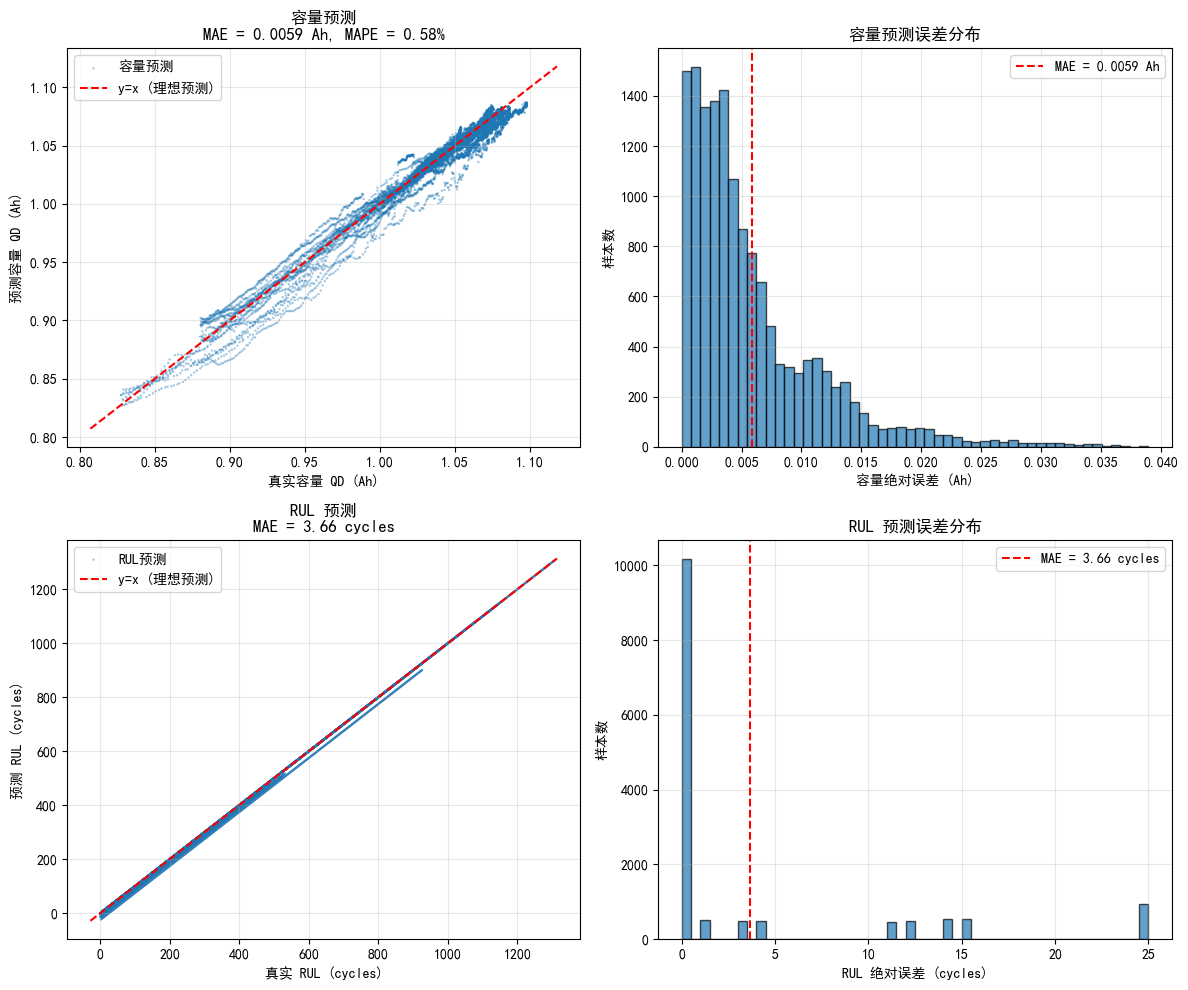

In [ ]:
# ============================================================
# 可视化：容量预测 vs 真实值
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# ---------- 容量散点图 ----------
ax = axes[0, 0]
ax.scatter(cap_gt, cap_pred, alpha=0.4, s=3, edgecolors='none', label='容量预测')
lims_cap = [min(cap_gt.min(), cap_pred.min()) - 0.02,
            max(cap_gt.max(), cap_pred.max()) + 0.02]   # x,y轴共用范围
ax.plot(lims_cap, lims_cap, 'r--', label='y=x (理想预测)')
ax.set_xlabel('真实容量 QD (Ah)'); ax.set_ylabel('预测容量 QD (Ah)')
ax.set_title(f"容量预测\nMAE = {cap_abs_err.mean():.4f} Ah, MAPE = {cap_mape:.2f}%")
ax.legend()
ax.grid(True, alpha=0.3)

# ---------- 误差分布直方图 ----------
ax = axes[0, 1]
ax.hist(cap_abs_err, bins=50, edgecolor='k', alpha=0.7)
ax.axvline(cap_abs_err.mean(), color='r', linestyle='--',
           label=f"MAE = {cap_abs_err.mean():.4f} Ah")
ax.set_xlabel('容量绝对误差 (Ah)'); ax.set_ylabel('样本数')
ax.set_title('容量预测误差分布')
ax.legend()
ax.grid(True, alpha=0.3)

# ---------- RUL 散点图 / RUL 峰窝图----------
ax = axes[1, 0]
ax.scatter(rul_true_all, rul_pred_all, alpha=0.4, s=3, edgecolors='none', label='RUL预测')
lims_rul = [min(rul_true_all.min(), rul_pred_all.min()) - 5,
            max(rul_true_all.max(), rul_pred_all.max()) + 5]
ax.plot(lims_rul, lims_rul, 'r--', label='y=x (理想预测)')
ax.set_xlabel('真实 RUL (cycles)'); ax.set_ylabel('预测 RUL (cycles)')
ax.set_title(f"RUL 预测\nMAE = {rul_abs_err.mean():.2f} cycles")
ax.legend()
ax.grid(True, alpha=0.3)
# ax = axes[1, 0]
# hb = ax.hexbin(rul_true_all, rul_pred_all, gridsize=50,
#                cmap='Blues', mincnt=1, bins='log', alpha=0.85)
# lims_rul = [min(rul_true_all.min(), rul_pred_all.min()) - 5,
#             max(rul_true_all.max(), rul_pred_all.max()) + 5]
# ax.plot(lims_rul, lims_rul, 'r--', label='y=x (理想预测)')
# ax.set_xlabel('真实 RUL (cycles)'); ax.set_ylabel('预测 RUL (cycles)')
# ax.set_title(f"RUL 预测\nMAE = {rul_abs_err.mean():.2f} cycles")
# ax.legend()
# ax.grid(True, alpha=0.3)
# fig.colorbar(hb, ax=ax).set_label('log(样本数)')

# ---------- RUL 误差分布直方图 ----------
ax = axes[1, 1]
ax.hist(rul_abs_err, bins=50, edgecolor='k', alpha=0.7)
ax.axvline(rul_abs_err.mean(), color='r', linestyle='--',
           label=f"MAE = {rul_abs_err.mean():.2f} cycles")
ax.set_xlabel('RUL 绝对误差 (cycles)'); ax.set_ylabel('样本数')
ax.set_title('RUL 预测误差分布')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


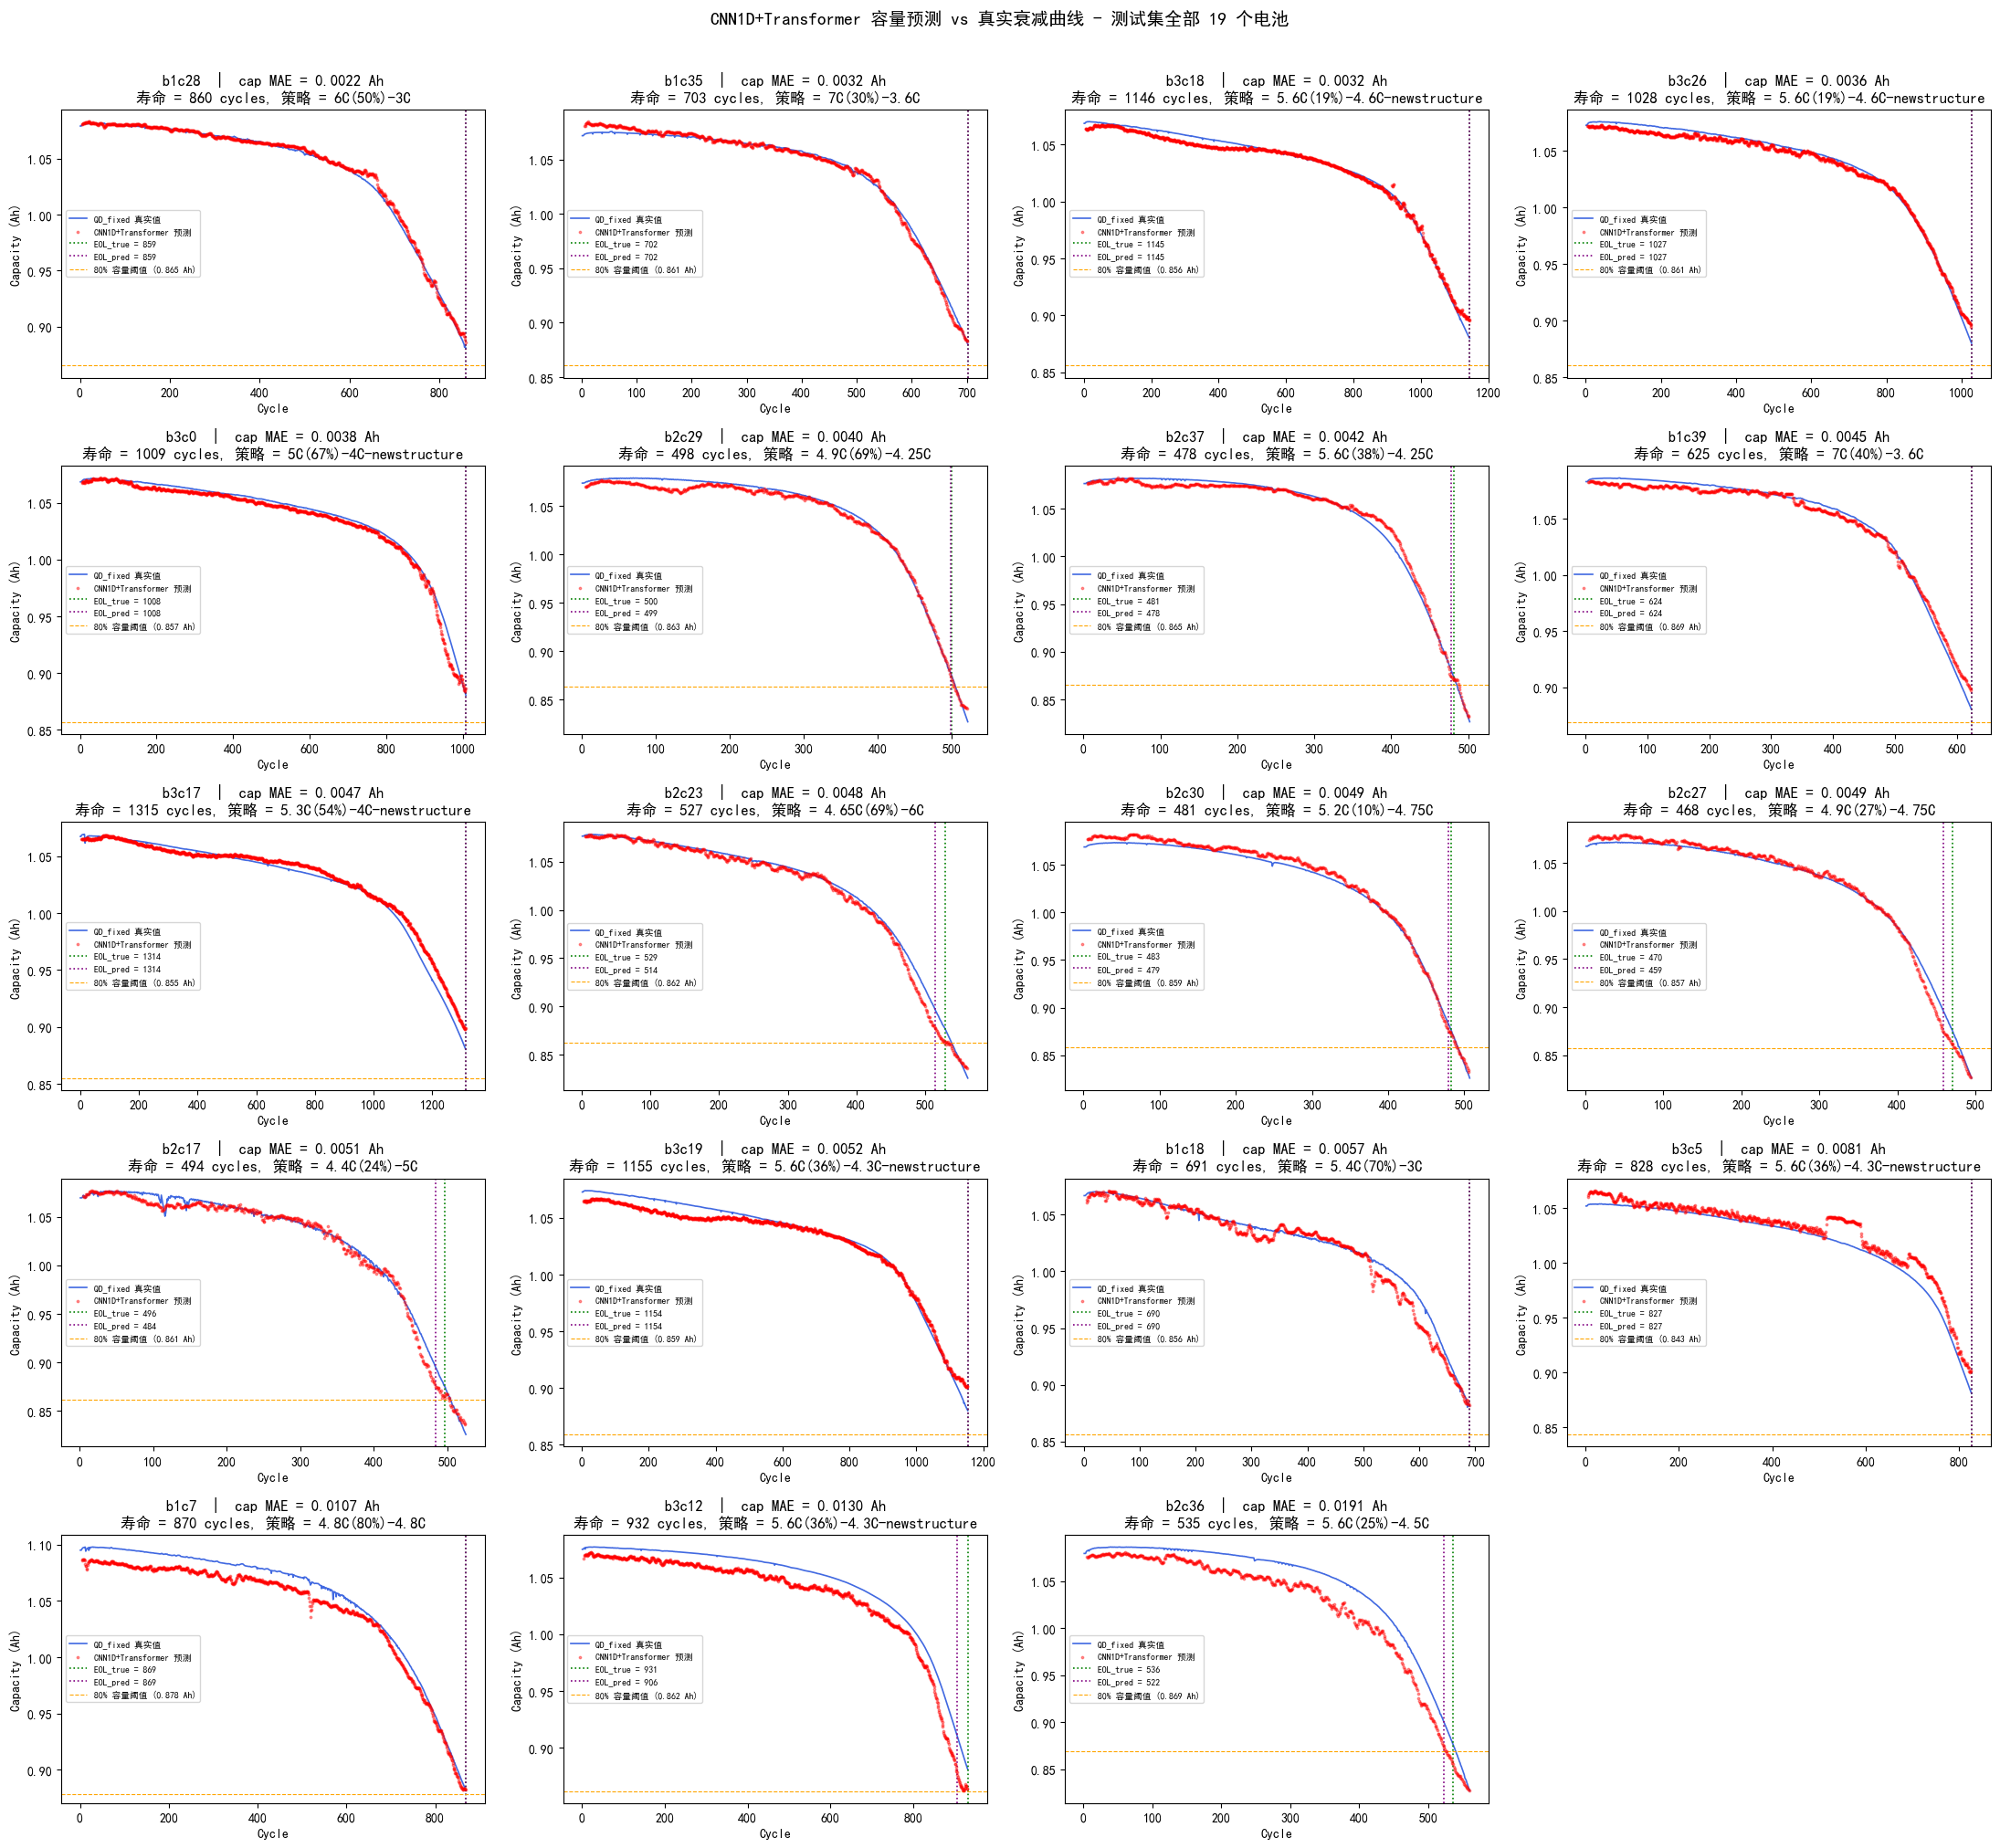

In [ ]:
# ============================================================
# 测试集所有电池：容量衰减 + 预测曲线可视化
# ============================================================

# 按容量 MAE 排序
bat_cap_mae = {}
for r in results:
    name = r["name"]
    b = bat_dict[name]
    qd_fixed = np.asarray(b["summary"]["QD_fixed"], dtype=np.float64)
    cycle_nums = np.asarray(b["summary"]["cycle"], dtype=np.int64)
    cycle_to_idx = {int(cn): i for i, cn in enumerate(cycle_nums)}
    errs = []
    for i, lc in enumerate(r["last_cycles"]):
        idx = cycle_to_idx.get(lc)
        if idx is not None:
            errs.append(abs(r["cap_preds"][i] - qd_fixed[idx]))
    if errs:
        bat_cap_mae[name] = np.mean(errs)

sorted_names = sorted(bat_cap_mae, key=bat_cap_mae.get)
n_bats = len(sorted_names)

# 根据电池数量动态确定网格尺寸
n_cols = 4
n_rows = int(np.ceil(n_bats / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5.5, n_rows * 4))
axes = axes.flatten()

# EOL 阈值：每电池 80% × 自身最大容量（与 cell 10 的 RUL 评估一致）

for i, name in enumerate(sorted_names):
    ax = axes[i]
    b = bat_dict[name]
    qd_fixed = np.asarray(b["summary"]["QD_fixed"], dtype=np.float64)
    cycle_nums = np.asarray(b["summary"]["cycle"], dtype=np.int64)
    eol = (rul_meta[name][1] if name in rul_meta
           else float(b["summary"]["eol_cycle"]))
    
    # 真实容量曲线（使用实际 cycle 编号作为 x 轴）
    ax.plot(cycle_nums, qd_fixed, linewidth=1.2, color="royalblue", label="QD_fixed 真实值")
    
    # 预测值（每个窗口末尾）
    r_match = [r_ for r_ in results if r_["name"] == name][0]
    ax.scatter(r_match["last_cycles"], r_match["cap_preds"], alpha=0.4, s=3,
               color="red", label="CNN1D+Transformer 预测", zorder=5)
    
    # EOL 线
    ax.axvline(eol, color="green", linestyle=":", linewidth=1.2,
               label=f"EOL_true = {eol:.0f}")
    # 预测 EOL（预测曲线上首次低于阈值）
    if name in rul_meta:
        eol_pred_b = rul_meta[name][0]
        ax.axvline(eol_pred_b, color="purple", linestyle=":", linewidth=1.2,
                   label=f"EOL_pred = {eol_pred_b:.0f}")
    # 每电池 80% 容量阈值
    thr_b = 0.8 * float(qd_fixed.max())
    ax.axhline(thr_b, color="orange", linestyle="--", linewidth=0.8,
               label=f"80% 容量阈值 ({thr_b:.3f} Ah)")
    
    # 构建标题（避免在 f-string 中使用反斜杠）
    title_line1 = f"{name}  |  cap MAE = {bat_cap_mae[name]:.4f} Ah"
    life = int(float(np.asarray(b['cycle_life']).ravel()[0]))
    title_line2 = f"寿命 = {life} cycles, 策略 = {b['charge_policy']}"
    ax.set_title(title_line1 + "\n" + title_line2)
    ax.set_xlabel("Cycle")
    ax.set_ylabel("Capacity (Ah)")
    ax.legend(fontsize=7)

# 隐藏多余的空白子图
for j in range(n_bats, len(axes)):
    axes[j].set_visible(False)

plt.suptitle(f"CNN1D+Transformer 容量预测 vs 真实衰减曲线 - 测试集全部 {n_bats} 个电池", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()
